# EDA de PlantVillage con CRISP-ML(Q)

**Objetivo:** caracterizar el conjunto de imágenes de hojas de `data/plantvillage/` para identificar enfermedades, detectar riesgos de calidad/fuga y producir artefactos reproducibles para el modelado.

## Relación con CRISP-ML(Q)

| Fase | Evidencia en este notebook |
|---|---|
| 1. Comprensión del problema y de los datos | objetivo, unidad de análisis, variable objetivo, alcance y limitaciones de PlantVillage |
| 2. Preparación de datos | inventario, etiquetas, formatos, integridad, normalización, duplicados y partición sin fuga |
| 3. Ingeniería/modelado | recomendaciones de entrada, normalización, balanceo y baseline; el entrenamiento vive en `src/leafthealthvision/` |
| 4. Evaluación | métricas recomendadas: macro-F1, balanced accuracy, recall por clase y matriz de confusión |
| 5. Despliegue y monitoreo | checklist de trazabilidad, deriva de distribución y monitoreo de clases nuevas/calidad |
| Calidad transversal (Q) | semilla fija, validaciones, supuestos explícitos, artefactos guardados y limitaciones declaradas |

> Este notebook implementa principalmente las fases 1 y 2. CRISP-ML(Q) no se cumple solo con un EDA: después deben documentarse modelado, evaluación, despliegue y monitoreo.

**Datos:** usa el dataset del repositorio en `data/plantvillage/` (descargable con `uv run python scripts/download_plantvillage.py`). Trabaja sobre la variante `segmented`, la misma de los manifiestos de `data/splits/`; `src/leafthealthvision/plantvillage.py` resuelve luego cada nombre a su equivalente en `raw/color` para entrenar.

## 0. Configuración y contrato de datos

El notebook usa la estructura del repositorio:

```text
data/plantvillage/
├── raw/
│   ├── color/<clase>/*.jpg
│   ├── grayscale/<clase>/*.jpg
│   └── segmented/<clase>/*.jpg
└── leaf_grouping/
    └── filtered_leafmaps/*.csv
```

La unidad de análisis es **una imagen** y la variable objetivo es `category` (por ejemplo, `Tomato___Late_blight`). No se debe mezclar `color`, `grayscale` y `segmented` como si fueran observaciones independientes: pueden representar la misma hoja.

In [10]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42  # convención del repo (src/leafthealthvision/config/settings.py)
random.seed(SEED)
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
plt.rcParams['figure.figsize'] = (14, 6)

# Raíz del proyecto: primer directorio hacia arriba con pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
DATA_DIR = ROOT / 'data' / 'plantvillage'
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f'No existe {DATA_DIR}. Descarga el dataset con: uv run python scripts/download_plantvillage.py'
    )
RAW_DIR = DATA_DIR / 'raw' if (DATA_DIR / 'raw').is_dir() else DATA_DIR
VARIANTES = [v for v in ('color', 'grayscale', 'segmented') if (RAW_DIR / v).is_dir()]
if not VARIANTES:
    raise FileNotFoundError(f'No se encontraron variantes en {RAW_DIR}')
VARIANTE_PRINCIPAL = 'segmented' if 'segmented' in VARIANTES else VARIANTES[0]

print('Raíz del proyecto:', ROOT)
print('Variantes:', VARIANTES, '| principal:', VARIANTE_PRINCIPAL)

Raíz del proyecto: c:\Users\ACER\Documents\Proyectos_ISCO\GitHub\LeaftHealthVision
Variantes: ['color', 'grayscale', 'segmented'] | principal: segmented


## 1. Inventario, volumen y variable objetivo

Se construye un registro por imagen. Se conserva la ruta completa y se crea un `id_imagen` único; no se usan solo los nombres de archivo porque podrían repetirse entre carpetas.

In [11]:
def iter_images(variant):
    base = RAW_DIR / variant
    for class_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        for path in sorted(class_dir.rglob('*')):
            if path.is_file() and path.suffix.lower() in IMG_EXT:
                yield path, class_dir.name

def normalized_stem(name):
    """Nombre sin UUID, extensión y sufijo _final_masked (equivale a image_core_name de src/leafthealthvision/plantvillage.py)."""
    stem = Path(name).stem.lower().strip().removesuffix('_final_masked')
    return stem.split('___', 1)[-1]

records = []
for variant in VARIANTES:
    for path, category in iter_images(variant):
        species = category.split('___', 1)[0]
        state = 'sano' if 'healthy' in category.lower() else 'enfermo'
        records.append({
            'id_imagen': f'{variant}|{category}|{path.name}',
            'variant': variant, 'path': str(path), 'filename': path.name,
            'category': category, 'species': species, 'state': state,
            'stem_normalized': normalized_stem(path.name),
            'extension': path.suffix.lower(), 'bytes': path.stat().st_size,
        })

df_all = pd.DataFrame(records)
df = df_all[df_all.variant.eq(VARIANTE_PRINCIPAL)].copy().reset_index(drop=True)
print('Total de imágenes:', len(df_all))
print(df_all.groupby('variant').size().to_string())
print('Clases:', df.category.nunique(), '| Especies:', df.species.nunique())
print('Sanas/enfermas:', df.state.value_counts().to_dict())

Total de imágenes: 162916
variant
color        54305
grayscale    54305
segmented    54306
Clases: 38 | Especies: 14
Sanas/enfermas: {'enfermo': 39222, 'sano': 15084}


                                          category  n_images  percentage  class_weight_balanced
          Orange___Haunglongbing_(Citrus_greening)      5507   10.140684               0.259507
            Tomato___Tomato_Yellow_Leaf_Curl_Virus      5357    9.864472               0.266773
                                 Soybean___healthy      5090    9.372813               0.280767
                            Peach___Bacterial_spot      2297    4.229735               0.622162
                           Tomato___Bacterial_spot      2127    3.916694               0.671888
                              Tomato___Late_blight      1909    3.515265               0.748615
                           Squash___Powdery_mildew      1835    3.379000               0.778804
                       Tomato___Septoria_leaf_spot      1771    3.261150               0.806948
     Tomato___Spider_mites Two-spotted_spider_mite      1676    3.086215               0.852688
                                   Apple

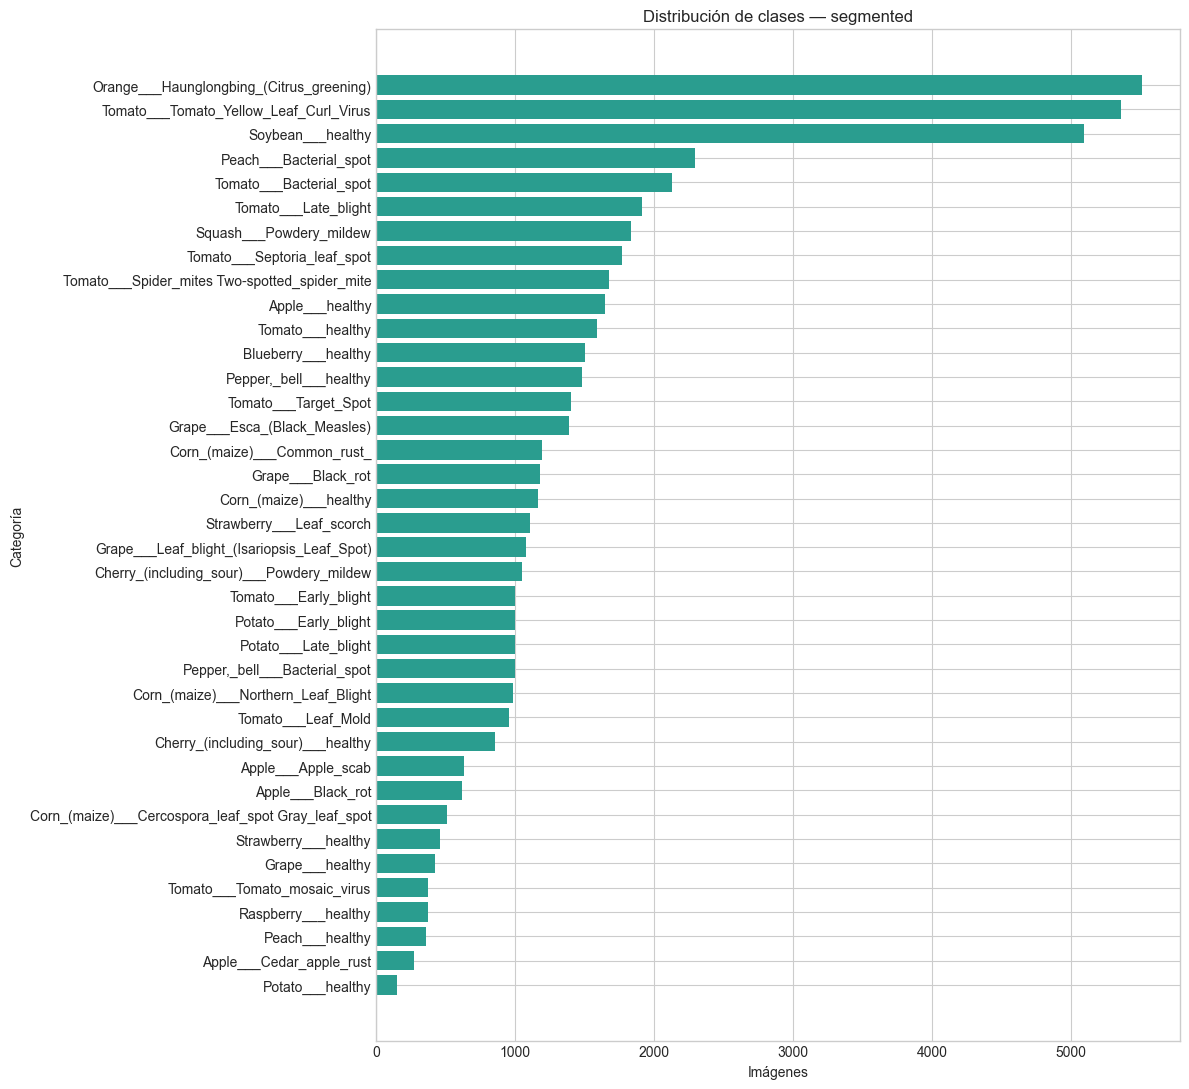

In [12]:
counts = df['category'].value_counts().rename_axis('category').reset_index(name='n_images')
counts['percentage'] = 100 * counts['n_images'] / len(df)
counts['class_weight_balanced'] = len(df) / (len(counts) * counts['n_images'])
print(counts.to_string(index=False))
print()
print('Ratio máximo/mínimo:', round(counts.n_images.max() / counts.n_images.min(), 2))
print('Coeficiente de variación:', round(counts.n_images.std(ddof=1) / counts.n_images.mean(), 3))

fig, ax = plt.subplots(figsize=(12, 11))
plot_df = counts.sort_values('n_images')
ax.barh(plot_df.category, plot_df.n_images, color='#2a9d8f')
ax.set(title=f'Distribución de clases — {VARIANTE_PRINCIPAL}', xlabel='Imágenes', ylabel='Categoría')
plt.tight_layout(); plt.show()

### Interpretación esperada

La accuracy global no es suficiente si hay desbalance. Para el modelo se deben reportar `macro-F1`, `balanced_accuracy`, `recall` y `precision` por clase. Los pesos calculados aquí son una referencia; deben estimarse solo con el conjunto de entrenamiento y validarse en el experimento.

## 2. Calidad técnica de las imágenes

Se decodifica cada imagen principal con `load()`. Esto detecta archivos que tienen una extensión válida pero están truncados o corruptos. También se reportan dimensiones y modos atípicos, sin asumir que todas las imágenes son idénticas.

In [13]:
quality=[]; corrupt=[]
for i, row in df.iterrows():
    path = Path(row.path)
    try:
        with Image.open(path) as im:
            reported_size, reported_mode, fmt = im.size, im.mode, im.format
            im.load()
        quality.append({**row.to_dict(), 'width': reported_size[0], 'height': reported_size[1], 'mode': reported_mode, 'format': fmt})
    except Exception as exc:
        corrupt.append({'id_imagen': row.id_imagen, 'path': str(path), 'error': repr(exc)})

meta = pd.DataFrame(quality)
corrupt_df = pd.DataFrame(corrupt)
print('Imágenes verificadas:', len(meta))
print('Corruptas/no decodificables:', len(corrupt_df))
print('Dimensiones más frecuentes:\n', meta.groupby(['width','height']).size().sort_values(ascending=False).head(10))
print('Modos:\n', meta['mode'].value_counts().to_string())
print('Atípicas respecto a 256x256 RGB:', int(((meta.width != 256) | (meta.height != 256) | (meta['mode'] != 'RGB')).sum()))
if len(corrupt_df): display(corrupt_df.head())

# Las imágenes que no pudieron decodificarse no entran al modelado ni al split.
valid_ids = set(meta['id_imagen'])
df = df[df['id_imagen'].isin(valid_ids)].copy().reset_index(drop=True)
classes = sorted(df.category.unique())
print('Imágenes válidas para el resto del EDA:', len(df))

Imágenes verificadas: 54306
Corruptas/no decodificables: 0
Dimensiones más frecuentes:
 width  height
256    256       54302
324    512           1
335    512           1
466    512           1
470    512           1
dtype: int64
Modos:
 mode
RGB    54305
L          1
Atípicas respecto a 256x256 RGB: 5
Imágenes válidas para el resto del EDA: 54306


## 3. Inspección visual y consistencia de variantes

La revisión visual es obligatoria: sirve para detectar etiquetas dudosas, fondo residual, hojas cortadas, iluminación extrema y diferencias de dominio. Las variantes de una misma imagen no deben contarse como nuevos ejemplos independientes.

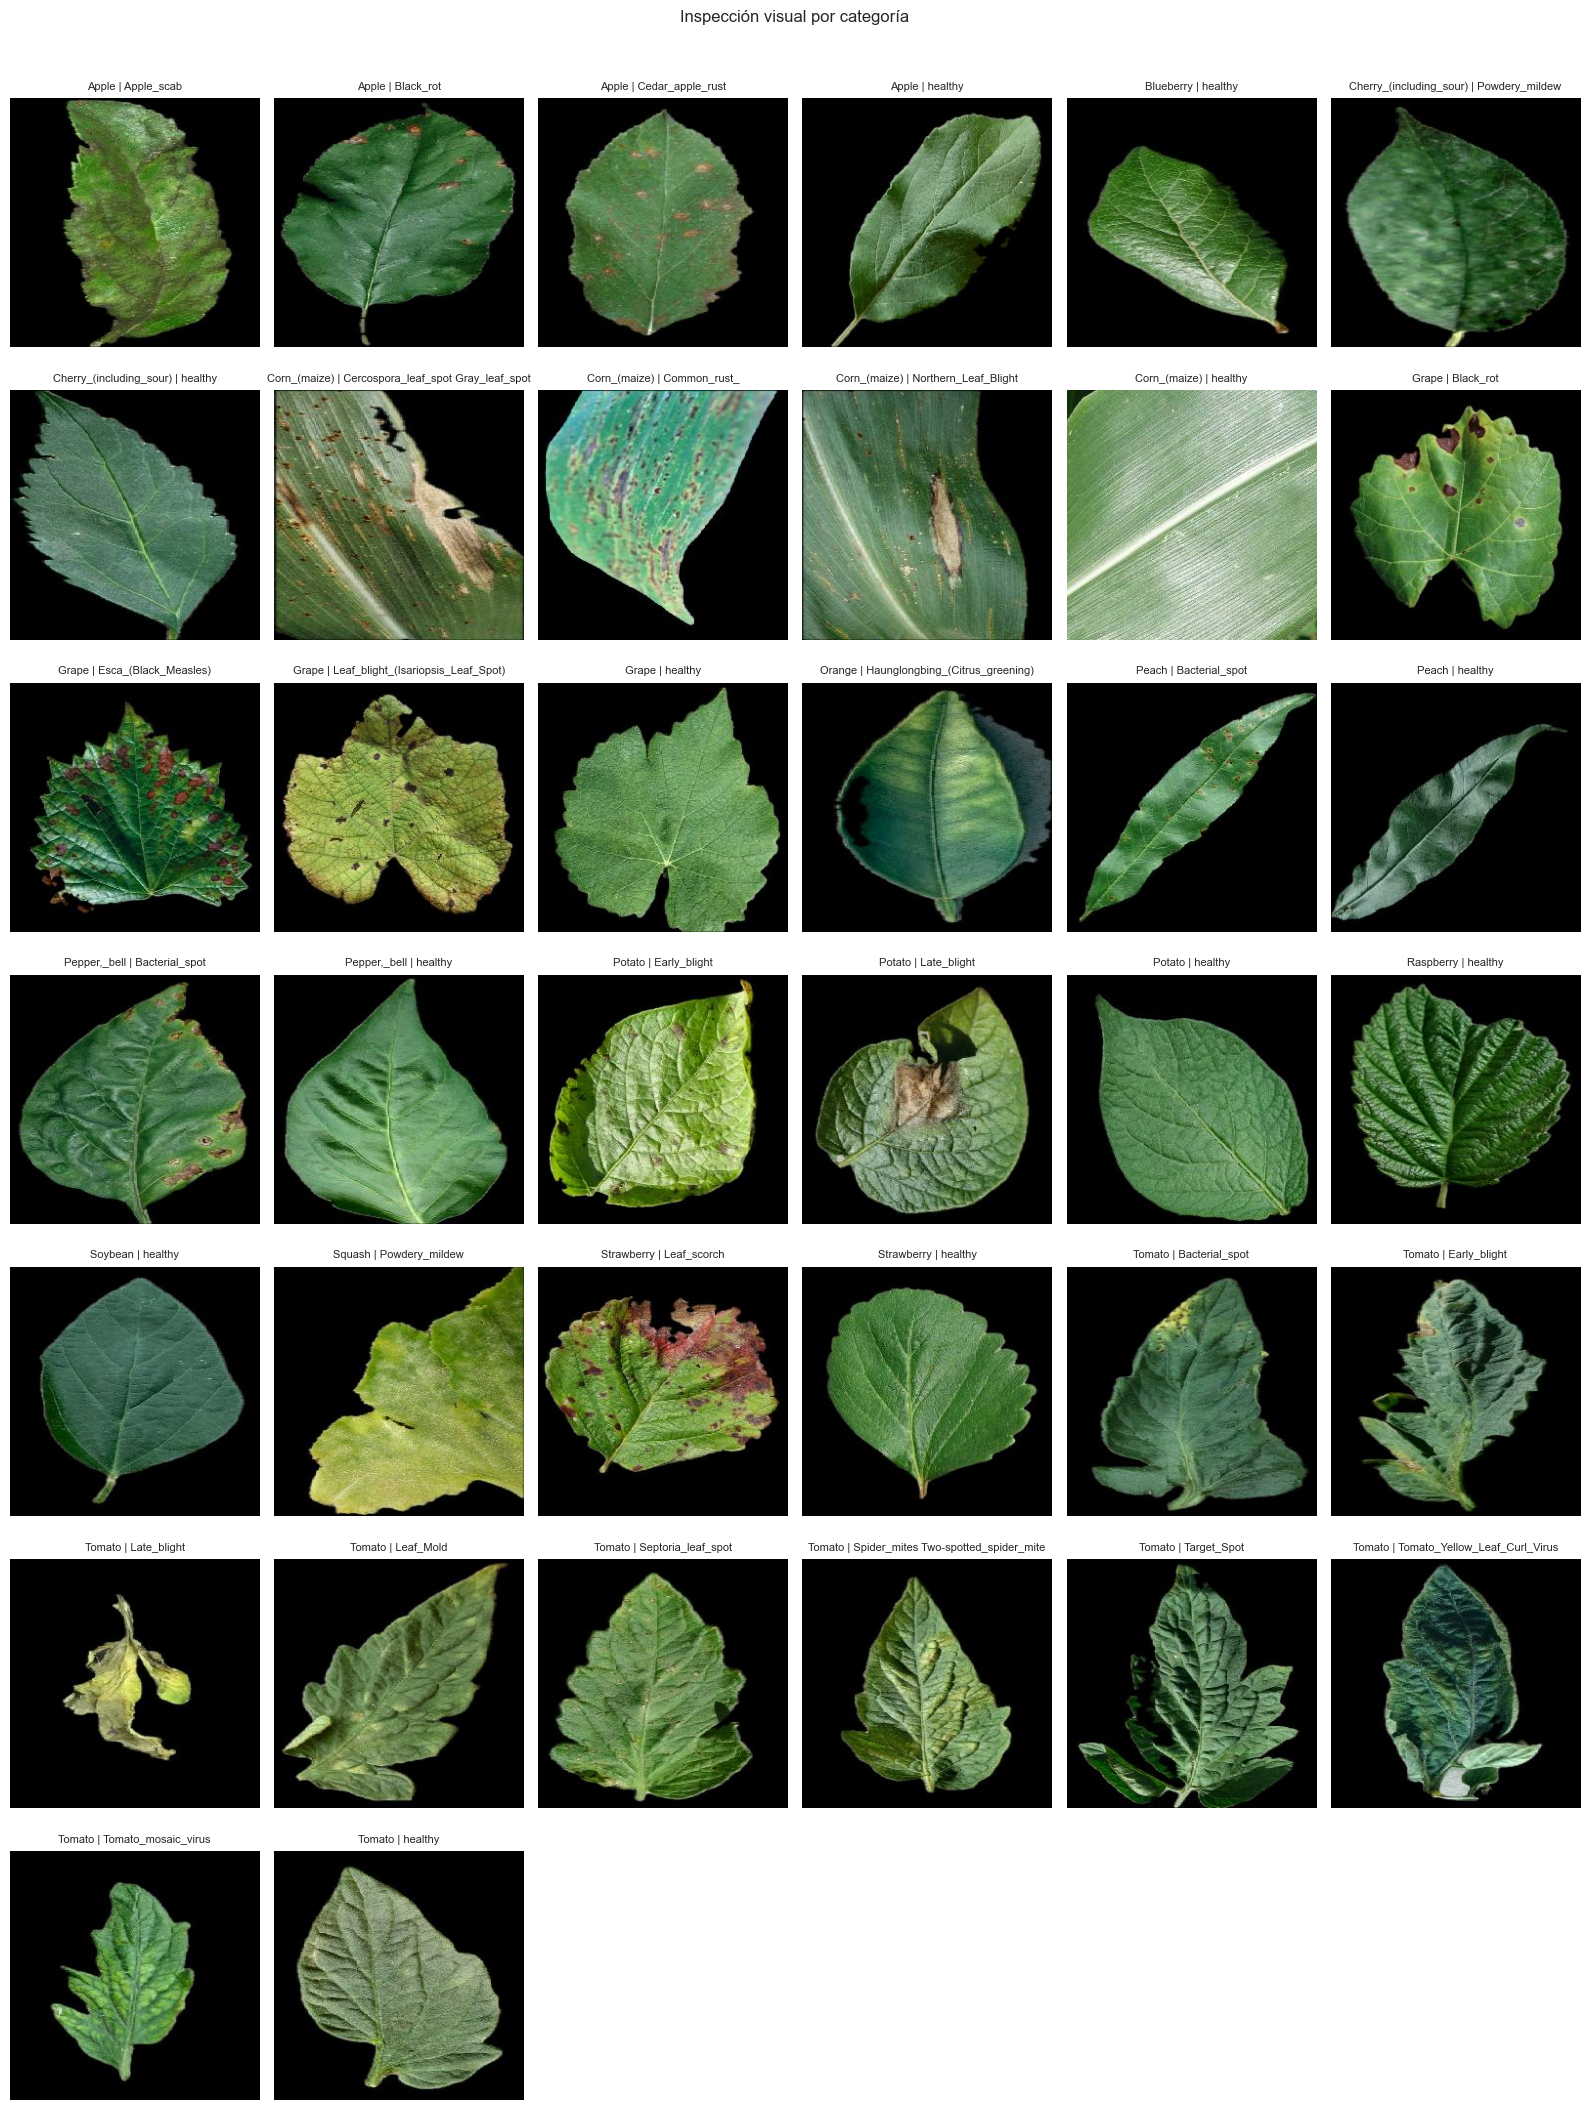

In [14]:
# Mosaico reproducible: hasta una imagen por clase.
classes = sorted(df.category.unique())
fig, axes = plt.subplots((len(classes)+5)//6, 6, figsize=(16, 3*((len(classes)+5)//6)))
axes = np.array(axes).reshape(-1)
for ax, category in zip(axes, classes):
    row = df[df.category.eq(category)].sample(1, random_state=SEED).iloc[0]
    with Image.open(row.path) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(category.replace('___',' | '), fontsize=8); ax.axis('off')
for ax in axes[len(classes):]: ax.axis('off')
plt.suptitle('Inspección visual por categoría', y=1.01); plt.tight_layout(); plt.show()

## 4. Metadatos de agrupación por hoja y riesgo de fuga

`filtered_leafmaps/*.csv` mapea `File Name` → `Leaf #`. Los nombres de los CSV suelen ser la categoría (p. ej. `Apple___Apple_scab.csv`), pero no todos (`Apple_Frogeye Spot.csv`); cuando el nombre no es una clase, se infiere por mayoría de coincidencias. Los `File Name` no traen UUID ni sufijo `_final_masked`, por eso el cruce usa `normalized_stem` y se restringe a la categoría del CSV: los nombres base se repiten entre categorías. Si una imagen no aparece en ningún CSV, su grupo queda como la propia imagen; **eso no demuestra ausencia total de fuga** para ese subconjunto, solo hace explícita la limitación.

`leaf-map.json` se descarta como fuente de grupos: sus valores son `categoría:::conteo_pixeles`, no nombres de archivo.

In [15]:
GROUPING_DIR = DATA_DIR / 'leaf_grouping'
csvs_dir = GROUPING_DIR / 'filtered_leafmaps'
classes_set = set(classes)
grupo_de = {}

if csvs_dir.is_dir():
    csvs = sorted(csvs_dir.glob('*.csv'))
    key_to_ids = defaultdict(list)
    for _, row in df.iterrows():
        key_to_ids[(row.category, row.stem_normalized)].append(row.id_imagen)
    filas_leidas = 0
    for csv_path in csvs:
        try:
            csv_df = pd.read_csv(csv_path, encoding='utf-8', encoding_errors='replace')
        except Exception:
            csv_df = pd.read_csv(csv_path, encoding='latin-1')
        if 'File Name' not in csv_df.columns:
            print('CSV sin columna File Name:', csv_path.name)
            continue
        stems = [normalized_stem(str(v).strip()) for v in csv_df['File Name']]
        leaves = [str(v).strip() for v in csv_df.get('Leaf #', [''] * len(stems))]
        filas_leidas += len(stems)
        # La categoría va en el nombre del CSV; si no, se infiere por mayoría de coincidencias.
        if csv_path.stem in classes_set:
            category = csv_path.stem
        else:
            votos = Counter(c for s in stems for c in classes if (c, s) in key_to_ids)
            category = votos.most_common(1)[0][0] if votos else None
        if category is None:
            print('CSV sin categoría inferida:', csv_path.name)
            continue
        for stem, leaf_no in zip(stems, leaves):
            for image_id in key_to_ids.get((category, stem), []):
                grupo_de[image_id] = f'{csv_path.name}|{leaf_no}'
    print('CSV encontrados:', len(csvs), '| filas leídas:', filas_leidas)
else:
    print('No se encontró leaf_grouping/filtered_leafmaps; se continuará sin grupos de hoja.')

df['leaf_group'] = df.id_imagen.map(grupo_de)
cobertura = df.leaf_group.notna().mean() * 100
print(f'Imágenes con grupo de hoja: {df.leaf_group.notna().sum()} ({cobertura:.1f}%)')
print('Grupos de hoja únicos:', df.leaf_group.nunique(dropna=True))
print('Imágenes por hoja, top frecuencias:', df.dropna(subset=['leaf_group']).groupby('leaf_group').size().value_counts().head().to_dict())

CSV encontrados: 31 | filas leídas: 42520
Imágenes con grupo de hoja: 41112 (75.7%)
Grupos de hoja únicos: 7595
Imágenes por hoja, top frecuencias: {4: 5455, 6: 411, 8: 324, 9: 293, 7: 279}


## 5. Estadísticas de píxeles y normalización

Se estiman estadísticas sobre una muestra estratificada, separando todos los píxeles de los píxeles no negros. Para un modelo preentrenado se puede iniciar con ImageNet; si se entrena desde cero, las estadísticas del entrenamiento son una alternativa. La decisión final se valida experimentalmente.

In [16]:
def pixel_stats(samples_per_class=30, nonblack_threshold=0.05):
    sums=np.zeros(3); sums2=np.zeros(3); n=0
    sums_h=np.zeros(3); sums2_h=np.zeros(3); n_h=0
    for category in classes:
        subset=df[df.category.eq(category)]
        for _, row in subset.sample(min(samples_per_class, len(subset)), random_state=SEED).iterrows():
            with Image.open(row.path) as im:
                arr=np.asarray(im.convert('RGB'), dtype=np.float64)/255.0
            pix=arr.reshape(-1,3); sums += pix.sum(0); sums2 += (pix**2).sum(0); n += len(pix)
            leaf=pix[pix.max(axis=1)>nonblack_threshold]
            sums_h += leaf.sum(0); sums2_h += (leaf**2).sum(0); n_h += len(leaf)
    def finish(s,s2,n):
        mean=s/n; std=np.sqrt(np.maximum(s2/n-mean**2, 0)); return mean,std
    return finish(sums,sums2,n), finish(sums_h,sums2_h,n_h)

(stats_all, stats_leaf) = pixel_stats()
print('Todos los píxeles | media, std:', [np.round(x,4).tolist() for x in stats_all])
print('Píxeles no negros | media, std:', [np.round(x,4).tolist() for x in stats_leaf])
print('Referencia ImageNet:', [0.485,0.456,0.406], [0.229,0.224,0.225])

Todos los píxeles | media, std: [[0.1817, 0.2436, 0.1448], [0.2205, 0.2725, 0.1853]]
Píxeles no negros | media, std: [[0.3687, 0.4945, 0.2933], [0.1736, 0.165, 0.1625]]
Referencia ImageNet: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]


## 6. Duplicados y partición sin fuga

Se detectan duplicados exactos por SHA-256. Después se asignan grupos completos a `train/val/test`: la prioridad es `leaf_group` y, cuando falta, se usa un identificador de imagen. Por clase se utiliza una partición determinista aproximada 80/10/10 con la semilla del proyecto. Si varias copias comparten hash, reciben el mismo grupo aunque solo se conserve una. Para las imágenes sin mapa de hoja, la partición es por imagen y la cobertura se reporta explícitamente.

In [17]:
def sha256_file(path, chunk=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(chunk), b''): h.update(block)
    return h.hexdigest()

df['sha256'] = [sha256_file(p) for p in df.path]
dup_groups = df.groupby('sha256').filter(lambda g: len(g)>1)
print('Grupos de duplicados exactos:', dup_groups.sha256.nunique())
print('Imágenes implicadas:', len(dup_groups), '| copias extra:', len(dup_groups)-dup_groups.sha256.nunique())

# Se conserva una copia por contenido; el grupo sale de la hoja si alguna copia la tiene.
agg = df.groupby('sha256').agg(
    id_ejemplo=('id_imagen', 'first'),
    hoja=('leaf_group', lambda s: s.dropna().iloc[0] if s.notna().any() else None),
)
hash_to_group = {h: (hoja if pd.notna(hoja) else 'IMAGE|' + iid) for h, iid, hoja in agg.itertuples()}

df_unique = df.sort_values('id_imagen').drop_duplicates('sha256').copy()
df_unique['group_id'] = df_unique.sha256.map(hash_to_group)

rng=np.random.default_rng(SEED); assignments={}
for category, subset in df_unique.groupby('category'):
    groups=list(subset.group_id.unique()); rng.shuffle(groups); n=len(groups)
    n_train=max(1, int(round(.80*n))); n_val=max(1, int(round(.10*n))) if n>=3 else 0
    if n>=3: n_train=min(n_train,n-2); n_val=min(n_val,n-n_train-1)
    for g in groups[:n_train]: assignments[g]='train'
    for g in groups[n_train:n_train+n_val]: assignments[g]='val'
    for g in groups[n_train+n_val:]: assignments[g]='test'
df_unique['split']=df_unique.group_id.map(assignments)

print('Únicas tras deduplicar:', len(df_unique))
print(df_unique.groupby('split').size().reindex(['train','val','test']).fillna(0).astype(int).to_string())
print('Grupos compartidos entre splits:', int((df_unique.groupby('group_id').split.nunique()>1).sum()))
print('Hashes compartidos entre splits:', int((df_unique.groupby('sha256').split.nunique()>1).sum()))
tabla = pd.crosstab(df_unique.category, df_unique.split).reindex(columns=['train','val','test'], fill_value=0)
print('Clases sin test:', int((tabla.test==0).sum()))
print('Cobertura por hoja: %.1f%%' % (df_unique.leaf_group.notna().mean()*100))

Grupos de duplicados exactos: 21
Imágenes implicadas: 42 | copias extra: 21
Únicas tras deduplicar: 54285
split
train    43486
val       5398
test      5401
Grupos compartidos entre splits: 0
Hashes compartidos entre splits: 0
Clases sin test: 0
Cobertura por hoja: 75.7%


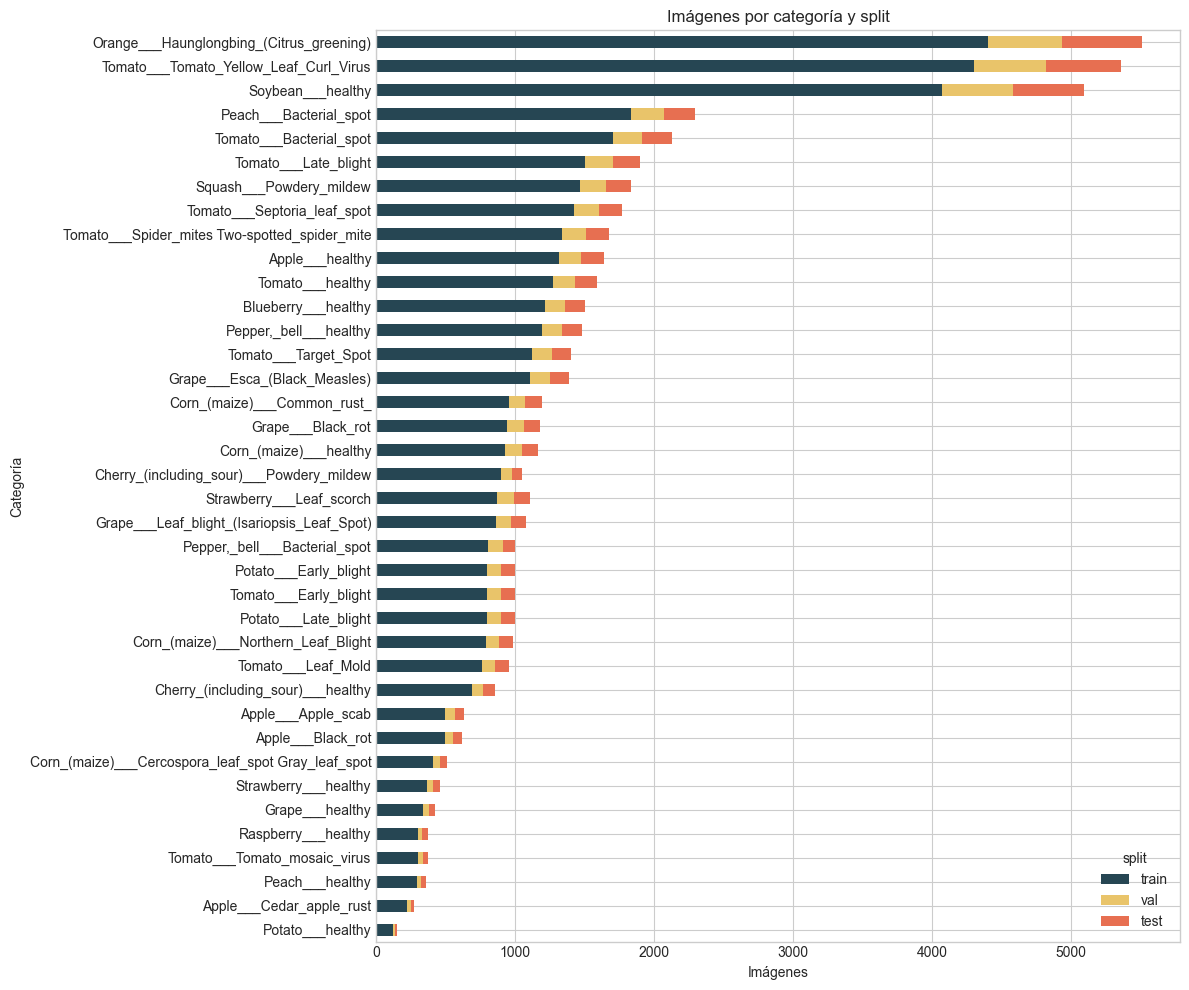

Artefactos EDA guardados en: c:\Users\ACER\Documents\Proyectos_ISCO\GitHub\LeaftHealthVision\data\eda_outputs
Manifiestos guardados en: c:\Users\ACER\Documents\Proyectos_ISCO\GitHub\LeaftHealthVision\data\splits
Clases por split: {'train': 38, 'val': 38, 'test': 38}


In [18]:
# Validación del balance por split y exportación de artefactos.
fig, ax = plt.subplots(figsize=(12,10))
tabla.sort_values('train').plot.barh(stacked=True, ax=ax, color=['#264653','#e9c46a','#e76f51'])
ax.set(title='Imágenes por categoría y split', xlabel='Imágenes', ylabel='Categoría'); plt.tight_layout(); plt.show()

OUTPUT_DIR = ROOT / 'data' / 'eda_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
counts.to_csv(OUTPUT_DIR/'class_distribution.csv', index=False)
meta.to_csv(OUTPUT_DIR/'image_metadata.csv', index=False)
if len(corrupt_df): corrupt_df.to_csv(OUTPUT_DIR/'corrupt_images.csv', index=False)

# Manifiestos en el formato que consume el entrenamiento (src/leafthealthvision/plantvillage.py).
splits_dir = ROOT / 'data' / 'splits'
splits_dir.mkdir(parents=True, exist_ok=True)
export = df_unique.rename(columns={'filename': 'archivo', 'category': 'categoria', 'leaf_group': 'hoja'})
export['origen'] = np.where(export.hoja.notna(), 'hoja', 'imagen')
for nombre, g in export.groupby('split'):
    g[['archivo','categoria','split','hoja','origen']].sort_values('archivo').to_csv(splits_dir/f'{nombre}.csv', index=False)

print('Artefactos EDA guardados en:', OUTPUT_DIR)
print('Manifiestos guardados en:', splits_dir)
print('Clases por split:', {n: export.loc[export.split.eq(n), 'categoria'].nunique() for n in ('train','val','test')})

# 7. Conclusiones CRISP-ML(Q) y plan de modelado

## Decisiones respaldadas por este EDA

1. **Unidad y etiquetas:** entrenar con una sola variante principal por experimento y conservar `category` como etiqueta multiclase; documentar que `healthy` se deriva del nombre de clase.
2. **Calidad:** excluir o transformar imágenes corruptas; convertir todas a RGB y redimensionar en el pipeline, no sobrescribir los originales.
3. **Desbalance:** usar pesos calculados únicamente desde `train`, focal loss o muestreo controlado; comparar contra un baseline sin corrección.
4. **Fuga:** particionar por hoja cuando exista el metadato y por contenido cuando no; no presentar el split por imagen como garantía equivalente al split por hoja.
5. **Evaluación:** reportar macro-F1, balanced accuracy, recall por clase, matriz de confusión y ejemplos de errores; incluir intervalos o advertir la alta varianza de clases pequeñas.
6. **Generalización:** PlantVillage suele tener condiciones controladas. Antes de afirmar utilidad en campo, se necesita un conjunto externo con iluminación, fondos, cámaras y cultivares diferentes.
7. **Artefactos:** `data/splits/{train,val,test}.csv` en el formato que consume `src/leafthealthvision/plantvillage.py` (columnas `archivo,categoria,split`); el entrenamiento resuelve cada imagen a `raw/color` sin regenerar la partición.

## Qué falta para cerrar CRISP-ML(Q)

- **Modelado:** baseline reproducible (por ejemplo, transfer learning), hiperparámetros, versionado de pesos y comparación de normalizaciones.
- **Evaluación:** conjunto de prueba bloqueado, análisis de errores y criterios de aceptación definidos antes de mirar resultados.
- **Despliegue:** contrato de entrada, validación de imagen, respuesta con confianza y manejo de "clase desconocida".
- **Monitoreo:** deriva de color/tamaño, proporción de imágenes rechazadas, distribución de clases, recall por clase y revisión humana de predicciones de baja confianza.
- **Calidad y reproducibilidad:** guardar semilla, versión del dataset, hash del manifiesto, entorno, código y fecha de ejecución.